# CC1 — Réseaux de neurones sur le dataset Iris
**Scikit-learn (`MLPClassifier`) vs TensorFlow/Keras**

## Introduction
Dans ce notebook, on résout **le même problème de classification** avec deux frameworks :
1. `MLPClassifier` de **Scikit-learn** ;
2. un réseau `Sequential` de **TensorFlow/Keras**.

**Problème** : à partir de 4 mesures d'une fleur (longueur/largeur du sépale et du pétale), prédire son espèce parmi 3 classes (*setosa*, *versicolor*, *virginica*).

C'est un problème de **classification multiclasse** → la métrique principale est l'**accuracy**.

> **Plan** : Dataset → Partie 1 (Scikit-learn) → Partie 2 (Keras) → Comparaison → Conclusion.

## Dataset Iris

In [1]:
# --- Bibliothèques générales ---
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, log_loss)

# Pour obtenir des résultats reproductibles
SEED = 42
np.random.seed(SEED)

### Chargement et exploration des données

In [2]:
# Chargement du dataset Iris (intégré à scikit-learn)
iris = load_iris()

# Transformation en DataFrame pour un affichage plus lisible
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

print("Premières lignes du dataset :")
display(df.head())

print("Dimensions du dataset (lignes, colonnes) :", df.shape)
print("Noms des variables :", iris.feature_names)
print("Classes :", list(iris.target_names))
print("Nombre d'exemples par classe :")
print(df['target'].value_counts().sort_index())

Premières lignes du dataset :


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dimensions du dataset (lignes, colonnes) : (150, 5)
Noms des variables : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Nombre d'exemples par classe :
target
0    50
1    50
2    50
Name: count, dtype: int64


Le dataset contient **150 fleurs**, **4 variables** numériques et **3 classes** parfaitement équilibrées (50 exemples chacune). Il n'y a pas de valeur manquante.

---
# Partie 1 : MLPClassifier — Scikit-learn

## Préparation des données
1. On sépare les **variables explicatives `X`** et la **cible `y`**.
2. On divise en **train (80 %)** / **test (20 %)**. `stratify=y` garde la même proportion de classes dans les deux ensembles.
3. On **standardise** les données (moyenne 0, écart-type 1). Les réseaux de neurones apprennent bien mieux avec des variables à la même échelle.

⚠️ Le `StandardScaler` est **ajusté (`fit`) uniquement sur le train**, puis appliqué au test, pour éviter toute fuite d'information.

In [3]:
# Séparation X / y
X = iris.data
y = iris.target

# Division train / test (80 % / 20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print("Train :", X_train.shape, " Test :", X_test.shape)

# Standardisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform sur le train
X_test_scaled = scaler.transform(X_test)         # transform seulement sur le test

Train : (120, 4)  Test : (30, 4)


## Entraînement
Architecture : `4 entrées → 10 neurones → 10 neurones → 3 classes`.
- `hidden_layer_sizes=(10, 10)` : deux couches cachées de 10 neurones ;
- `max_iter=1000` : nombre maximum d'itérations (epochs) ;
- `random_state` : reproductibilité.

In [4]:
mlp_clf = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, random_state=SEED)

start = time.time()
mlp_clf.fit(X_train_scaled, y_train)
time_sk_iris = time.time() - start

print(f"Entraînement terminé en {time_sk_iris:.3f} s ({mlp_clf.n_iter_} itérations)")

Entraînement terminé en 0.148 s (603 itérations)


## Prédiction et Accuracy

In [5]:
y_pred_sk = mlp_clf.predict(X_test_scaled)

acc_sk = accuracy_score(y_test, y_pred_sk)
print(f"Accuracy (test) MLPClassifier : {acc_sk:.4f}")

Accuracy (test) MLPClassifier : 0.9667


## Matrice de confusion et rapport de classification
La matrice de confusion montre, pour chaque classe réelle (lignes), quelle classe a été prédite (colonnes). Une matrice parfaite est diagonale.

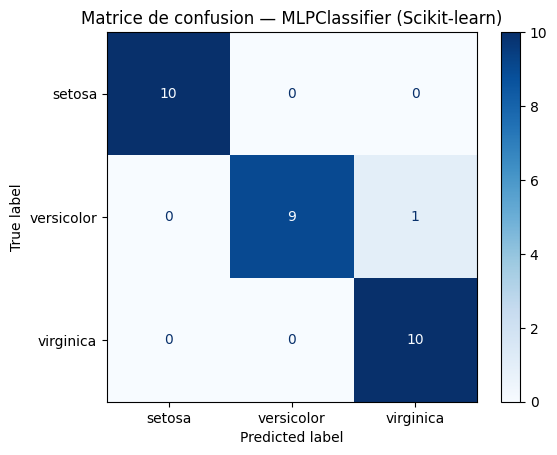

Classification report :
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [6]:
cm_sk = confusion_matrix(y_test, y_pred_sk)
ConfusionMatrixDisplay(cm_sk, display_labels=iris.target_names).plot(cmap='Blues')
plt.title("Matrice de confusion — MLPClassifier (Scikit-learn)")
plt.show()

print("Classification report :")
print(classification_report(y_test, y_pred_sk, target_names=iris.target_names))

## Courbe de loss
`loss_curve_` contient la valeur de la loss (log-loss) à chaque itération d'entraînement.

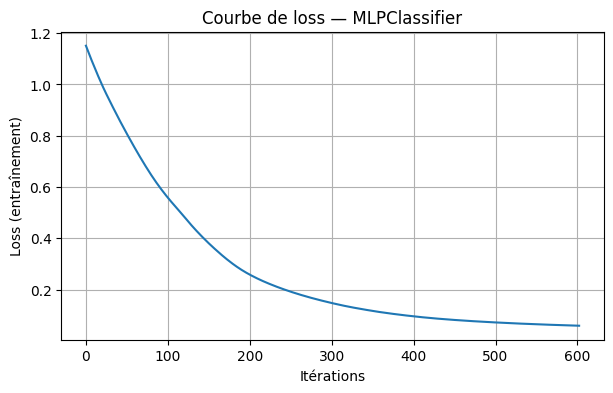

Loss finale (entraînement) : 0.0590


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(mlp_clf.loss_curve_)
plt.title("Courbe de loss — MLPClassifier")
plt.xlabel("Itérations")
plt.ylabel("Loss (entraînement)")
plt.grid(True)
plt.show()

print(f"Loss finale (entraînement) : {mlp_clf.loss_curve_[-1]:.4f}")

## Interprétation — Scikit-learn

*(Valeurs observées lors de l'exécution du notebook ; elles peuvent varier légèrement selon la machine et la version des bibliothèques.)*

- L'**accuracy sur le test est de 0,9667** : sur 30 fleurs, **une seule** est mal classée.
- La matrice de confusion et le rapport montrent que **setosa est parfaitement reconnue** (précision et rappel = 1,00). Les seules confusions concernent **versicolor / virginica**, deux espèces dont les mesures se chevauchent.
- La **courbe de loss décroît** régulièrement puis se stabilise : le réseau a bien convergé (loss finale ≈ 0,06).
- ⚠️ Le jeu de test ne contient que 30 exemples : une seule erreur fait varier l'accuracy de ≈ 3,3 points. Il faut donc rester prudent dans l'interprétation.

---
# Partie 2 : TensorFlow/Keras — Classification Iris

## Préparation
On réutilise **exactement les mêmes données** que dans la Partie 1 : même chargement, même découpage train/test, même standardisation. Ainsi la comparaison entre les deux frameworks est équitable.

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Reproductibilité
tf.keras.utils.set_random_seed(SEED)

print("Version de TensorFlow :", tf.__version__)
print("Données identiques à la partie 1 :", X_train_scaled.shape, X_test_scaled.shape)

I0000 00:00:1791469357.276542    1929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791469358.815896    1929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Version de TensorFlow : 2.21.0
Données identiques à la partie 1 : (120, 4) (30, 4)


## Construction du réseau
Architecture : `4 variables → Dense(16, ReLU) → Dense(8, ReLU) → Dense(3, Softmax)`.
- **ReLU** dans les couches cachées : fonction d'activation simple et efficace ;
- **Softmax** en sortie : transforme les 3 sorties en **probabilités** dont la somme vaut 1.

In [9]:
model_iris = Sequential([
    Input(shape=(4,)),                 # 4 variables d'entrée
    Dense(16, activation='relu'),      # 1re couche cachée
    Dense(8, activation='relu'),       # 2e couche cachée
    Dense(3, activation='softmax')     # sortie : 3 classes
])

model_iris.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   # classes codées en entiers 0, 1, 2
    metrics=['accuracy']
)

model_iris.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## Entraînement
`validation_split=0.2` réserve 20 % du train pour surveiller le modèle sur des données qu'il n'utilise pas pour apprendre (on peut ainsi détecter le sur-apprentissage).

In [10]:
start = time.time()
history_iris = model_iris.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0          # mettre 1 pour voir la progression
)
time_keras_iris = time.time() - start
print(f"Entraînement terminé en {time_keras_iris:.2f} s")

Entraînement terminé en 15.26 s


## Évaluation, prédiction, accuracy

In [11]:
# Évaluation sur le jeu de test
test_loss_keras, test_acc_keras = model_iris.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Loss (test)     : {test_loss_keras:.4f}")
print(f"Accuracy (test) : {test_acc_keras:.4f}")

# Prédictions : le modèle renvoie 3 probabilités par fleur -> on prend la plus grande
proba_keras = model_iris.predict(X_test_scaled, verbose=0)
y_pred_keras = np.argmax(proba_keras, axis=1)

acc_keras = accuracy_score(y_test, y_pred_keras)
print(f"Accuracy recalculée avec scikit-learn : {acc_keras:.4f}")

Loss (test)     : 0.2336
Accuracy (test) : 0.9333
Accuracy recalculée avec scikit-learn : 0.9333


## Matrice de confusion

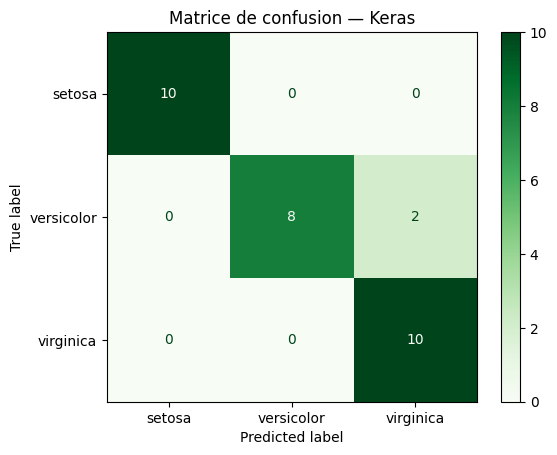

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [12]:
cm_keras = confusion_matrix(y_test, y_pred_keras)
ConfusionMatrixDisplay(cm_keras, display_labels=iris.target_names).plot(cmap='Greens')
plt.title("Matrice de confusion — Keras")
plt.show()

print(classification_report(y_test, y_pred_keras, target_names=iris.target_names))

## Courbes d'apprentissage

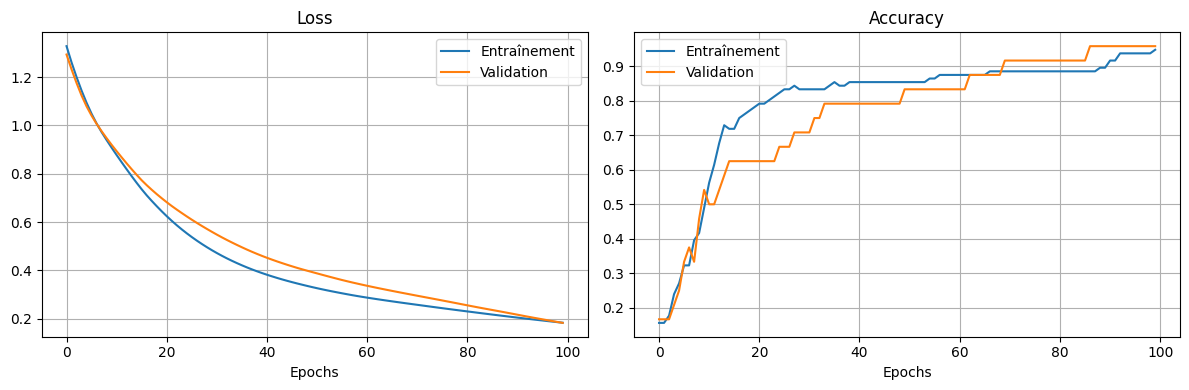

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_iris.history['loss'], label='Entraînement')
axes[0].plot(history_iris.history['val_loss'], label='Validation')
axes[0].set_title("Loss"); axes[0].set_xlabel("Epochs"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history_iris.history['accuracy'], label='Entraînement')
axes[1].plot(history_iris.history['val_accuracy'], label='Validation')
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epochs"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

## Interprétation — Keras

- L'**accuracy sur le test est de 0,9333** (28 fleurs sur 30 bien classées), avec une loss de test ≈ 0,23.
- Comme pour Scikit-learn, **setosa est parfaitement classée** et les erreurs sont entre **versicolor et virginica**.
- Les courbes **loss/accuracy d'entraînement et de validation évoluent dans le même sens** : la loss diminue, l'accuracy monte. On n'observe pas de sur-apprentissage marqué. (Le jeu de validation étant très petit — 24 exemples — la courbe de validation est un peu bruitée.)

---
# Comparaison Sklearn vs Keras

On compare les deux modèles sur le **même jeu de test**. Pour comparer la *loss* de façon équitable, on calcule la **log-loss sur le test** pour les deux modèles (c'est la même quantité que la *cross-entropy* de Keras).

,Modèle,Framework,Accuracy,Loss (test),Temps entraînement (s),Architecture,Nb paramètres
0,MLPClassifier,Scikit-learn,0.9667,0.0849,0.1476,4-10-10-3 (ReLU),193
1,Neural Network,TensorFlow/Keras,0.9333,0.2336,15.2632,4-16-8-3 (ReLU + Softmax),243


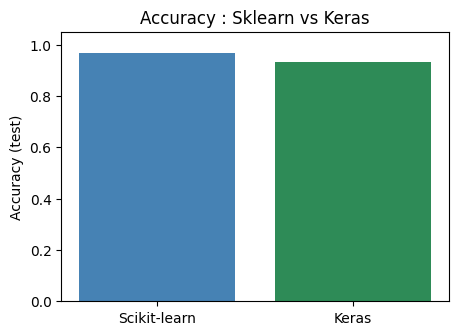

➜ Meilleure accuracy : MLPClassifier (Scikit-learn)


In [14]:
loss_sk_test = log_loss(y_test, mlp_clf.predict_proba(X_test_scaled))
loss_keras_test = log_loss(y_test, proba_keras)

n_params_sk = sum(w.size for w in mlp_clf.coefs_) + sum(b.size for b in mlp_clf.intercepts_)

comparison_iris = pd.DataFrame({
    'Modèle': ['MLPClassifier', 'Neural Network'],
    'Framework': ['Scikit-learn', 'TensorFlow/Keras'],
    'Accuracy': [acc_sk, acc_keras],
    'Loss (test)': [loss_sk_test, loss_keras_test],
    'Temps entraînement (s)': [time_sk_iris, time_keras_iris],
    'Architecture': ['4-10-10-3 (ReLU)', '4-16-8-3 (ReLU + Softmax)'],
    'Nb paramètres': [n_params_sk, model_iris.count_params()],
})
display(comparison_iris.round(4))

# Graphique comparatif des accuracies
plt.figure(figsize=(5, 3.5))
plt.bar(['Scikit-learn', 'Keras'], [acc_sk, acc_keras], color=['steelblue', 'seagreen'])
plt.ylim(0, 1.05); plt.ylabel("Accuracy (test)"); plt.title("Accuracy : Sklearn vs Keras")
plt.show()

# Verdict automatique (calculé, pas écrit à la main)
if acc_sk > acc_keras:
    print("➜ Meilleure accuracy : MLPClassifier (Scikit-learn)")
elif acc_keras > acc_sk:
    print("➜ Meilleure accuracy : Neural Network (Keras)")
else:
    print("➜ Accuracy identique pour les deux modèles ; on départage avec la loss :",
          "Scikit-learn" if loss_sk_test < loss_keras_test else "Keras", "a la plus faible loss.")

| Critère | Scikit-learn | TensorFlow/Keras |
|---|---|---|
| Facilité d'utilisation | Très simple : `fit` / `predict` en quelques lignes | Un peu plus long : définir les couches, `compile`, `fit` |
| Contrôle de l'architecture | Limité (taille des couches) | Total (couches, activations, régularisation, callbacks…) |
| Suivi de l'entraînement | `loss_curve_` seulement | Historique complet (train **et** validation) |
| Temps d'entraînement | Généralement plus rapide sur de petits jeux de données | Surcoût de TensorFlow sur petit dataset |


### Interprétation
Lors de notre exécution, **`MLPClassifier` obtient une accuracy légèrement supérieure (0,9667 contre 0,9333)** et une loss de test plus faible. **Attention** : l'écart correspond à **une seule fleur** sur un test de 30 exemples ; il n'est donc pas statistiquement significatif. On peut conclure que **les deux modèles ont des performances très proches**, ce qui est normal car Iris est un problème simple et presque linéairement séparable.

La différence la plus nette est le **temps d'entraînement** : Scikit-learn est beaucoup plus rapide ici (le surcoût de TensorFlow n'est pas amorti sur 120 exemples). Les deux modèles ont par ailleurs des architectures et des nombres de paramètres différents (193 vs 243), ce qui rend la comparaison approximative.